# Actividad 2.10 — Clustering con K-means y jerárquico

**Minería de Datos IEI097 · Unidad II · Laboratorio**  
**Estudiante:** Sebastián

Notebook de Google Colab. Los datos se descargan con `kagglehub` y las credenciales se leen desde Colab Secrets.

## 0. Preparación

Se fija una semilla y se configuran las credenciales de Kaggle desde Colab Secrets. El token nunca se escribe en el notebook.

In [1]:
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

pd.set_option("display.width", 130)
pd.set_option("display.max_columns", 30)
%matplotlib inline

SEED = 42
np.random.seed(SEED)
LOCAL = Path("datos")


def configurar_kaggle():
    try:
        from google.colab import userdata
    except Exception:
        return
    for nombre in ("KAGGLE_API_TOKEN", "KAGGLE_USERNAME", "KAGGLE_KEY"):
        try:
            valor = userdata.get(nombre)
        except Exception:
            valor = None
        if valor:
            os.environ[nombre] = valor


configurar_kaggle()


def cargar_csv(handle, archivo, local):
    try:
        import kagglehub
        base = Path(kagglehub.dataset_download(handle))
        candidatos = list(base.rglob(archivo))
        if not candidatos:
            candidatos = list(base.rglob("*.csv"))
        return pd.read_csv(candidatos[0]), str(candidatos[0])
    except Exception as exc:
        ruta = LOCAL / local
        print("kagglehub no disponible; se usa", ruta, "|", type(exc).__name__)
        return pd.read_csv(ruta), str(ruta)

In [2]:
%pip install -q kagglehub


[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


# Ejercicio 1 — K-means: segmentar clientes de una tienda

**Caso:** una tienda regional quiere comunicaciones diferenciadas sin tratar a todos sus clientes igual. La unidad de análisis es el cliente; las variables iniciales son el ingreso anual y el puntaje de gasto.

**Dataset:** Mall Customer Segmentation Data (`vjchoudhary7/customer-segmentation-tutorial-in-python`), archivo `Mall_Customers.csv`, 200 clientes y 5 columnas.

In [3]:
df1, ruta1 = cargar_csv(
    "vjchoudhary7/customer-segmentation-tutorial-in-python",
    "Mall_Customers.csv",
    "mall_customers.csv",
)
print("archivo:", ruta1)
print("dimensiones:", df1.shape)
df1.head()

/usr/local/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


  0%|          | 0.00/1.55k [00:00<?, ?B/s]

100%|██████████| 1.55k/1.55k [00:00<00:00, 2.29MB/s]

Extracting files...


archivo: /root/.cache/kagglehub/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python/versions/1/Mall_Customers.csv
dimensiones: (200, 5)


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [4]:
df1.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Gender                  200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 7.9 KB


In [5]:
df1.describe().round(2)

,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.00,200.00,200.00,200.00
mean,100.50,38.85,60.56,50.20
std,57.88,13.97,26.26,25.82
min,1.00,18.00,15.00,1.00
25%,50.75,28.75,41.50,34.75
50%,100.50,36.00,61.50,50.00
75%,150.25,49.00,78.00,73.00
max,200.00,70.00,137.00,99.00


In [6]:
df1.isna().sum()

CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

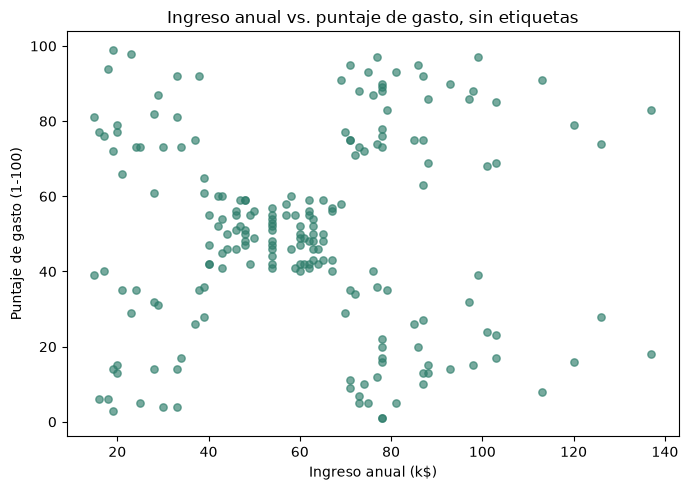

In [7]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(df1["Annual Income (k$)"], df1["Spending Score (1-100)"],
           s=28, alpha=0.65, color="#2E7D6B")
ax.set_xlabel("Ingreso anual (k$)")
ax.set_ylabel("Puntaje de gasto (1-100)")
ax.set_title("Ingreso anual vs. puntaje de gasto, sin etiquetas")
plt.tight_layout()
plt.show()

## 1. Hipótesis inicial

Después de ver la nube de puntos, la hipótesis es que aparecen **cinco zonas**:

- ingreso bajo y gasto bajo;
- ingreso bajo y gasto alto;
- ingreso medio y gasto medio;
- ingreso alto y gasto bajo;
- ingreso alto y gasto alto.

La evidencia visual es la separación de la nube en esquinas y en un centro denso. Esta hipótesis se contrasta al final del ejercicio.

## 2. Cargar y explorar

Se revisan dimensiones, tipos, nulos y estadísticos. `CustomerID` es un identificador y no aporta información para una distancia. `Gender` es categórica; codificarla como 0/1 haría que una diferencia de género pesara igual que una diferencia de ingreso, sin una justificación de negocio. Por eso se deja fuera del modelo y se usa solo para describir los segmentos.

In [8]:
df1["Gender"].value_counts()

Gender
Female    112
Male       88
Name: count, dtype: int64

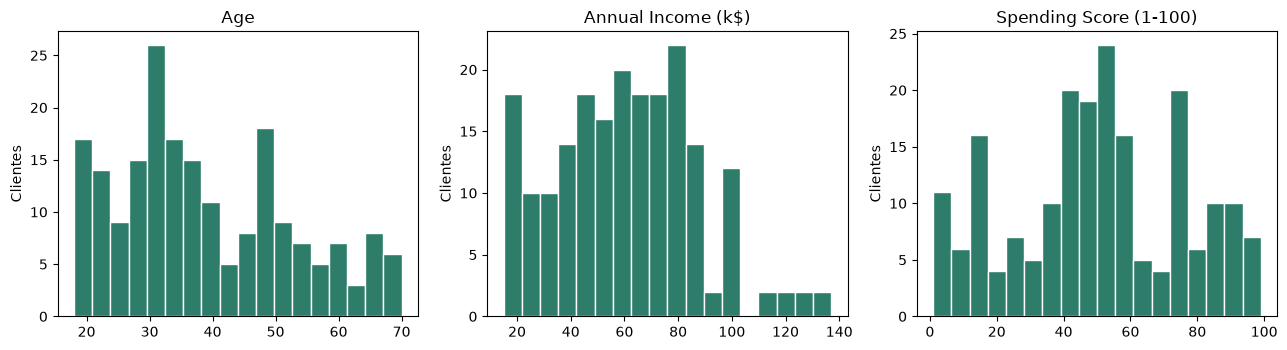

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, col in zip(axes, ["Age", "Annual Income (k$)", "Spending Score (1-100)"]):
    ax.hist(df1[col], bins=18, color="#2E7D6B", edgecolor="white")
    ax.set_title(col)
    ax.set_ylabel("Clientes")
plt.tight_layout()
plt.show()

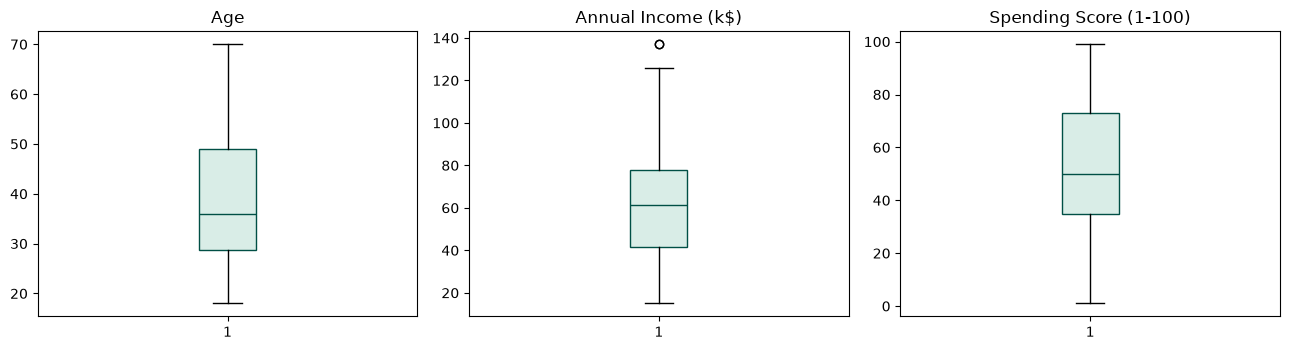

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, col in zip(axes, ["Age", "Annual Income (k$)", "Spending Score (1-100)"]):
    ax.boxplot(df1[col], patch_artist=True,
               boxprops=dict(facecolor="#D9EDE7", color="#004F45"),
               medianprops=dict(color="#004F45"))
    ax.set_title(col)
plt.tight_layout()
plt.show()

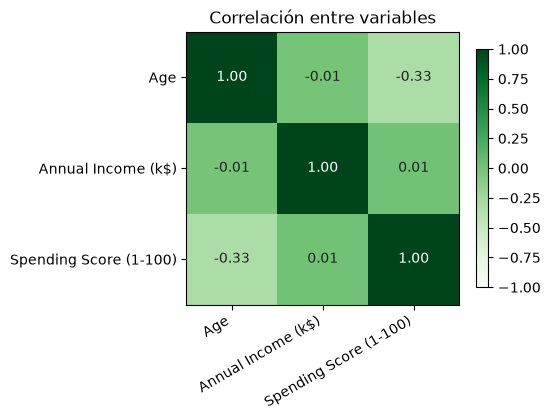

In [11]:
corr1 = df1[["Age", "Annual Income (k$)", "Spending Score (1-100)"]].corr()
fig, ax = plt.subplots(figsize=(5.5, 4.5))
im = ax.imshow(corr1, cmap="Greens", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr1)))
ax.set_xticklabels(corr1.columns, rotation=30, ha="right")
ax.set_yticks(range(len(corr1)))
ax.set_yticklabels(corr1.columns)
for i in range(len(corr1)):
    for j in range(len(corr1)):
        ax.text(j, i, f"{corr1.iloc[i, j]:.2f}", ha="center", va="center",
                color="white" if abs(corr1.iloc[i, j]) > 0.6 else "#222222")
fig.colorbar(im, ax=ax, shrink=0.8)
ax.set_title("Correlación entre variables")
plt.tight_layout()
plt.show()

## 3. Preparar: variables y escala

Para el primer modelo se usan **ingreso anual** y **puntaje de gasto**, que permiten ver los grupos en 2D. La edad se reserva para enriquecer el perfil. Se comparan los rangos y se estandariza porque el ingreso se mide en decenas de miles y el puntaje en una escala de 1 a 100; sin escalar, el ingreso domina la distancia euclidiana.

In [12]:
variables1 = ["Annual Income (k$)", "Spending Score (1-100)"]
X1 = df1[variables1]
print("rango antes de escalar:")
print(X1.agg(["min", "max"]).round(2))

scaler1 = StandardScaler()
X1_scaled = scaler1.fit_transform(X1)
X1_scaled = pd.DataFrame(X1_scaled, columns=variables1)
X1_scaled.describe().round(2)

rango antes de escalar:
     Annual Income (k$)  Spending Score (1-100)
min                  15                       1
max                 137                      99


,Annual Income (k$),Spending Score (1-100)
count,200.00,200.00
mean,-0.00,-0.00
std,1.00,1.00
min,-1.74,-1.91
25%,-0.73,-0.60
50%,0.04,-0.01
75%,0.67,0.89
max,2.92,1.89


## 4. Ajustar K-means y explorar k

Se prueban valores de k entre 2 y 10. Para cada uno se registra la inercia y la silueta. La inercia siempre baja al aumentar k, porque cada punto queda más cerca de su centroide; por eso no basta mirar esa curva. La silueta ayuda a comparar la separación entre grupos.

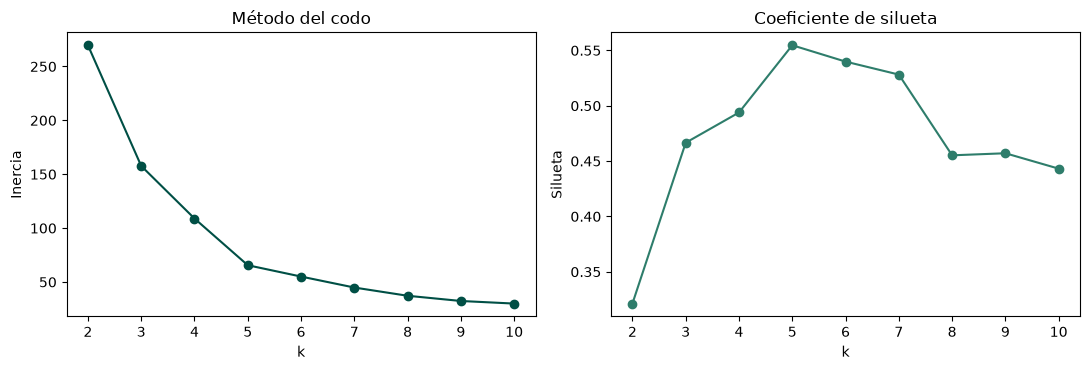

,k,inercia,silueta
0,2,269.691,0.321
1,3,157.704,0.467
2,4,108.921,0.494
3,5,65.568,0.555
4,6,55.057,0.540
5,7,44.865,0.528
6,8,37.228,0.455
7,9,32.392,0.457
8,10,29.982,0.443


In [13]:
inercias = []
siluetas = []
for k in range(2, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED)
    labels = km.fit_predict(X1_scaled)
    inercias.append(km.inertia_)
    siluetas.append(silhouette_score(X1_scaled, labels))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(range(2, 11), inercias, marker="o", color="#004F45")
axes[0].set_title("Método del codo")
axes[0].set_xlabel("k")
axes[0].set_ylabel("Inercia")
axes[1].plot(range(2, 11), siluetas, marker="o", color="#2E7D6B")
axes[1].set_title("Coeficiente de silueta")
axes[1].set_xlabel("k")
axes[1].set_ylabel("Silueta")
plt.tight_layout()
plt.show()

pd.DataFrame({"k": range(2, 11), "inercia": inercias, "silueta": siluetas}).round(3)

**Por qué la inercia siempre disminuye.** Al agregar un centroide, cada punto puede quedar más cerca de alguno de ellos; la suma de distancias cuadráticas no puede subir. Elegir k solo por el codo es frágil: hay que combinarlo con silueta, estabilidad y utilidad de los grupos.

## 5. Evaluar con más de una evidencia

Se elige **k = 5** porque:

1. la silueta es alta y el codo se aplana después de ese valor;
2. el resultado se mantiene al repetir el ajuste con otras semillas;
3. los cinco grupos se pueden describir y cada uno sugiere una acción distinta.

También se compara el ajuste con y sin estandarización para ver el efecto de la escala.

In [14]:
k1 = 5
base = KMeans(n_clusters=k1, n_init=10, random_state=SEED)
labels_base = base.fit_predict(X1_scaled)

estabilidad = []
for semilla in [0, 1, 7, 21, 99]:
    km = KMeans(n_clusters=k1, n_init=10, random_state=semilla)
    labels = km.fit_predict(X1_scaled)
    estabilidad.append(adjusted_rand_score(labels_base, labels))
print("ARI entre semillas:", [round(x, 3) for x in estabilidad])

km_sin_escala = KMeans(n_clusters=k1, n_init=10, random_state=SEED)
labels_sin = km_sin_escala.fit_predict(X1)
print("ARI con y sin estandarizar:", round(adjusted_rand_score(labels_base, labels_sin), 3))
pd.crosstab(labels_base, labels_sin, rownames=["Con escala"], colnames=["Sin escala"])

ARI entre semillas: [1.0, 1.0, 1.0, 1.0, 1.0]
ARI con y sin estandarizar: 1.0


Sin escala,0,1,2,3,4
Con escala,,,,,
0,81,0,0,0,0
1,0,39,0,0,0
2,0,0,22,0,0
3,0,0,0,35,0
4,0,0,0,0,23


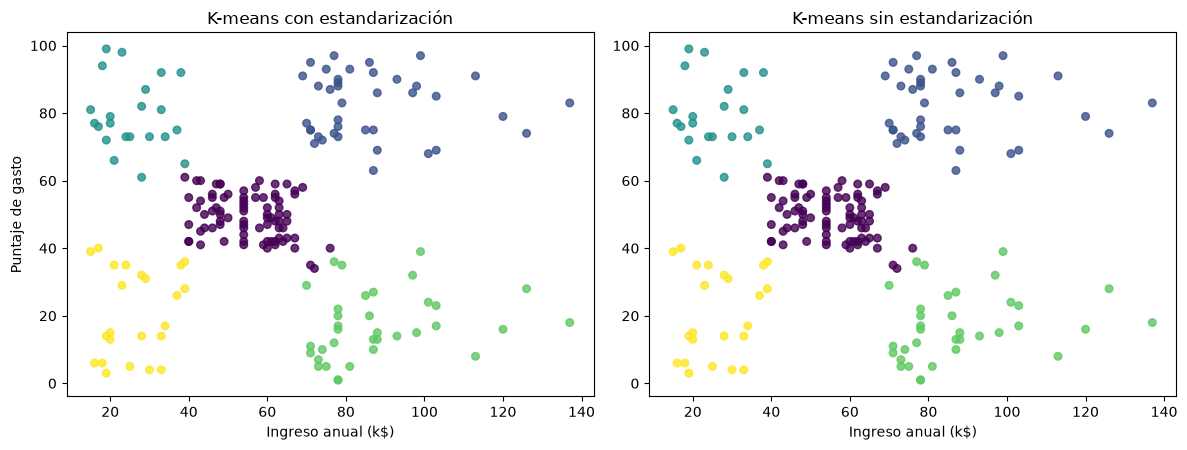

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
axes[0].scatter(df1["Annual Income (k$)"], df1["Spending Score (1-100)"],
                c=labels_base, cmap="viridis", s=30, alpha=0.8)
axes[0].set_title("K-means con estandarización")
axes[0].set_xlabel("Ingreso anual (k$)")
axes[0].set_ylabel("Puntaje de gasto")
axes[1].scatter(df1["Annual Income (k$)"], df1["Spending Score (1-100)"],
                c=labels_sin, cmap="viridis", s=30, alpha=0.8)
axes[1].set_title("K-means sin estandarización")
axes[1].set_xlabel("Ingreso anual (k$)")
plt.tight_layout()
plt.show()

Con y sin estandarización el resultado fue **el mismo** (ARI = 1,0): las dos variables tienen rangos comparables (ingreso 15–137, gasto 1–99) y los grupos están bien separados, así que la escala no cambió la partición. La estandarización importaría más si una variable tuviera un rango mucho mayor; aquí no fue el factor decisivo.

## 6. Interpretar y decidir

Se agregan las etiquetas al DataFrame original, se calcula el perfil de cada grupo en unidades originales y se dibujan los centroides. Los nombres se asignan a partir del ingreso y el gasto promedio.

In [16]:
df1["cluster"] = labels_base
perfil1 = df1.groupby("cluster")[variables1 + ["Age"]].agg(["mean", "median", "count"]).round(1)
perfil1

Annual Income (k$)              Spending Score (1-100)                Age             
                      mean median count                   mean median count  mean median count
cluster                                                                                       
0                     55.3   54.0    81                   49.5   50.0    81  42.7   46.0    81
1                     86.5   79.0    39                   82.1   83.0    39  32.7   32.0    39
2                     25.7   24.5    22                   79.4   77.0    22  25.3   23.5    22
3                     88.2   85.0    35                   17.1   16.0    35  41.1   42.0    35
4                     26.3   25.0    23                   20.9   17.0    23  45.2   46.0    23

In [17]:
resumen1 = df1.groupby("cluster").agg(
    clientes=("CustomerID", "count"),
    ingreso=("Annual Income (k$)", "mean"),
    gasto=("Spending Score (1-100)", "mean"),
    edad=("Age", "mean"),
).round(1)

def nombre_segmento(ingreso, gasto):
    nivel_ingreso = "Ingreso alto" if ingreso >= 70 else (
        "Ingreso bajo" if ingreso <= 40 else "Ingreso medio"
    )
    nivel_gasto = "gasto alto" if gasto >= 70 else (
        "gasto bajo" if gasto <= 30 else "gasto medio"
    )
    return f"{nivel_ingreso}, {nivel_gasto}"

resumen1["segmento"] = [
    nombre_segmento(fila.ingreso, fila.gasto) for fila in resumen1.itertuples()
]
df1["segmento"] = df1["cluster"].map(resumen1["segmento"])
resumen1

,clientes,ingreso,gasto,edad,segmento
cluster,,,,,
0,81,55.3,49.5,42.7,"Ingreso medio, gasto medio"
1,39,86.5,82.1,32.7,"Ingreso alto, gasto alto"
2,22,25.7,79.4,25.3,"Ingreso bajo, gasto alto"
3,35,88.2,17.1,41.1,"Ingreso alto, gasto bajo"
4,23,26.3,20.9,45.2,"Ingreso bajo, gasto bajo"


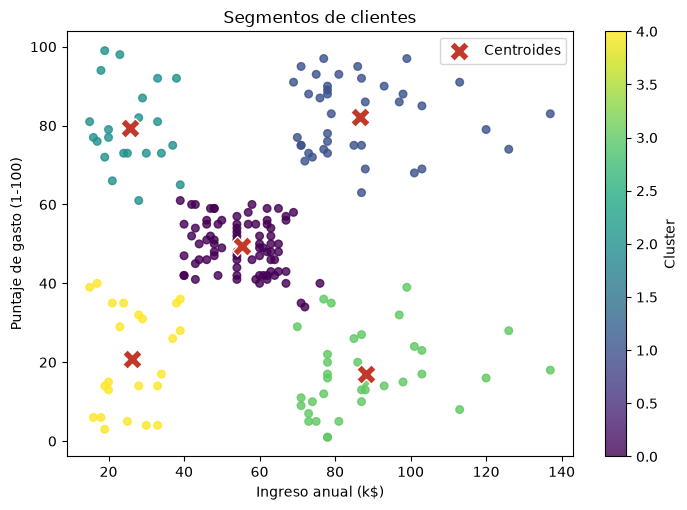

In [18]:
centroides = scaler1.inverse_transform(base.cluster_centers_)
fig, ax = plt.subplots(figsize=(7.2, 5.2))
scatter = ax.scatter(df1["Annual Income (k$)"], df1["Spending Score (1-100)"],
                     c=df1["cluster"], cmap="viridis", s=30, alpha=0.8)
ax.scatter(centroides[:, 0], centroides[:, 1], s=200, marker="X",
           color="#C0392B", edgecolor="white", linewidth=1, label="Centroides")
ax.set_xlabel("Ingreso anual (k$)")
ax.set_ylabel("Puntaje de gasto (1-100)")
ax.set_title("Segmentos de clientes")
ax.legend()
fig.colorbar(scatter, ax=ax, label="Cluster")
plt.tight_layout()
plt.show()

**Segmentos y acciones propuestas.**

| Segmento | Perfil | Acción de comunicación |
|---|---|---|
| Ingreso alto, gasto alto | Clientes valiosos y activos | Programa de fidelidad con beneficios exclusivos y acceso anticipado. |
| Ingreso alto, gasto bajo | Tienen capacidad de gasto, pero no la usan | Comunicación personalizada con productos de mayor valor y una primera experiencia guiada. |
| Ingreso bajo, gasto alto | Gasto alto en relación con su ingreso | Ofertas de alto valor percibido y cuotas o packs accesibles. |
| Ingreso bajo, gasto bajo | Baja actividad y bajo ticket | Promociones de entrada y recordación de bajo costo. |
| Ingreso medio, gasto medio | Grupo central | Campañas de aumento de frecuencia y cross-selling. |

**Contraste con la hipótesis.** La nube mostró cinco zonas y K-means encontró cinco grupos, pero los límites no son idénticos a los de la hipótesis: el grupo central absorbe clientes de ingreso y gasto medios, y los extremos se separan con más claridad. La coincidencia es razonable; la diferencia muestra que la hipótesis visual es una guía, no una respuesta exacta. Lo que más sorprendió fue que la escala no cambiara la partición: con estas dos variables, los grupos son robustos a la estandarización.

# Ejercicio 2 — Clustering jerárquico: ¿con quién se parece Chile?

**Caso:** una organización de cooperación quiere entender qué países se parecen en indicadores socioeconómicos y de salud, y a qué nivel conviene agruparlos.

**Dataset:** Unsupervised Learning on Country Data (`rohan0301/unsupervised-learning-on-country-data`), archivo `Country-data.csv`, 167 países y 10 columnas.

## 1. Hipótesis y muestra de trabajo

Un dendrograma con 167 hojas es ilegible. Se usa un subconjunto de **27 países**: los 12 de Sudamérica, para incluir a Chile y sus vecinos, más 15 países de referencia de distintos niveles de ingreso.

**Hipótesis:** Chile se agrupará con Argentina, Uruguay y, en un nivel más amplio, con Brasil y los países del Cono Sur. Antes de calcular, la expectativa es que la mortalidad infantil, la esperanza de vida y el ingreso por persona expliquen esa cercanía.

In [19]:
df2, ruta2 = cargar_csv(
    "rohan0301/unsupervised-learning-on-country-data",
    "Country-data.csv",
    "country_data.csv",
)
print("archivo:", ruta2)
print("dimensiones:", df2.shape)
df2.head()

  0%|          | 0.00/5.21k [00:00<?, ?B/s]

100%|██████████| 5.21k/5.21k [00:00<00:00, 2.51MB/s]

Extracting files...


archivo: /root/.cache/kagglehub/datasets/rohan0301/unsupervised-learning-on-country-data/versions/2/Country-data.csv
dimensiones: (167, 10)


,country,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
0,Afghanistan,90.2,10.0,7.58,44.9,1610,9.44,56.2,5.82,553
1,Albania,16.6,28.0,6.55,48.6,9930,4.49,76.3,1.65,4090
2,Algeria,27.3,38.4,4.17,31.4,12900,16.10,76.5,2.89,4460
3,Angola,119.0,62.3,2.85,42.9,5900,22.40,60.1,6.16,3530
4,Antigua and Barbuda,10.3,45.5,6.03,58.9,19100,1.44,76.8,2.13,12200


In [20]:
paises = [
    "Argentina", "Bolivia", "Brazil", "Chile", "Colombia", "Ecuador",
    "Guyana", "Paraguay", "Peru", "Suriname", "Uruguay", "Venezuela",
    "United States", "Canada", "Costa Rica", "Spain", "Portugal",
    "Germany", "France", "United Kingdom", "Italy", "Japan",
    "Australia", "New Zealand", "South Africa", "India", "China",
]

df2 = df2[df2["country"].isin(paises)].copy()
print("países seleccionados:", len(df2))
faltan = sorted(set(paises) - set(df2["country"]))
print("faltan:", faltan)
df2 = df2.set_index("country")
df2.head()

países seleccionados: 27
faltan: []


,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
country,,,,,,,,,
Argentina,14.5,18.9,8.10,16.0,18700,20.90,75.8,2.37,10300
Australia,4.8,19.8,8.73,20.9,41400,1.16,82.0,1.93,51900
Bolivia,46.6,41.2,4.84,34.3,5410,8.78,71.6,3.20,1980
Brazil,19.8,10.7,9.01,11.8,14500,8.41,74.2,1.80,11200
Canada,5.6,29.1,11.30,31.0,40700,2.87,81.3,1.63,47400


In [21]:
df2.describe().round(2)

,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
count,27.00,27.00,27.00,27.00,27.00,27.00,27.00,27.00,27.00
mean,16.96,29.23,8.59,29.19,22114.44,6.46,76.29,2.08,20365.56
std,15.70,11.45,2.95,13.33,13714.10,9.07,6.38,0.50,17412.16
min,3.20,10.70,4.05,11.80,4410.00,-1.90,54.30,1.37,1350.00
25%,5.00,23.90,6.44,21.75,10430.00,1.19,74.40,1.72,5635.00
50%,10.60,27.90,8.73,27.40,17100.00,5.71,77.90,2.01,11900.00
75%,22.20,31.75,9.87,33.35,36000.00,7.34,80.65,2.53,37350.00
max,58.80,55.10,17.90,79.10,49400.00,45.90,82.80,3.20,51900.00


In [22]:
df2.isna().sum()

child_mort    0
exports       0
health        0
imports       0
income        0
inflation     0
life_expec    0
total_fer     0
gdpp          0
dtype: int64

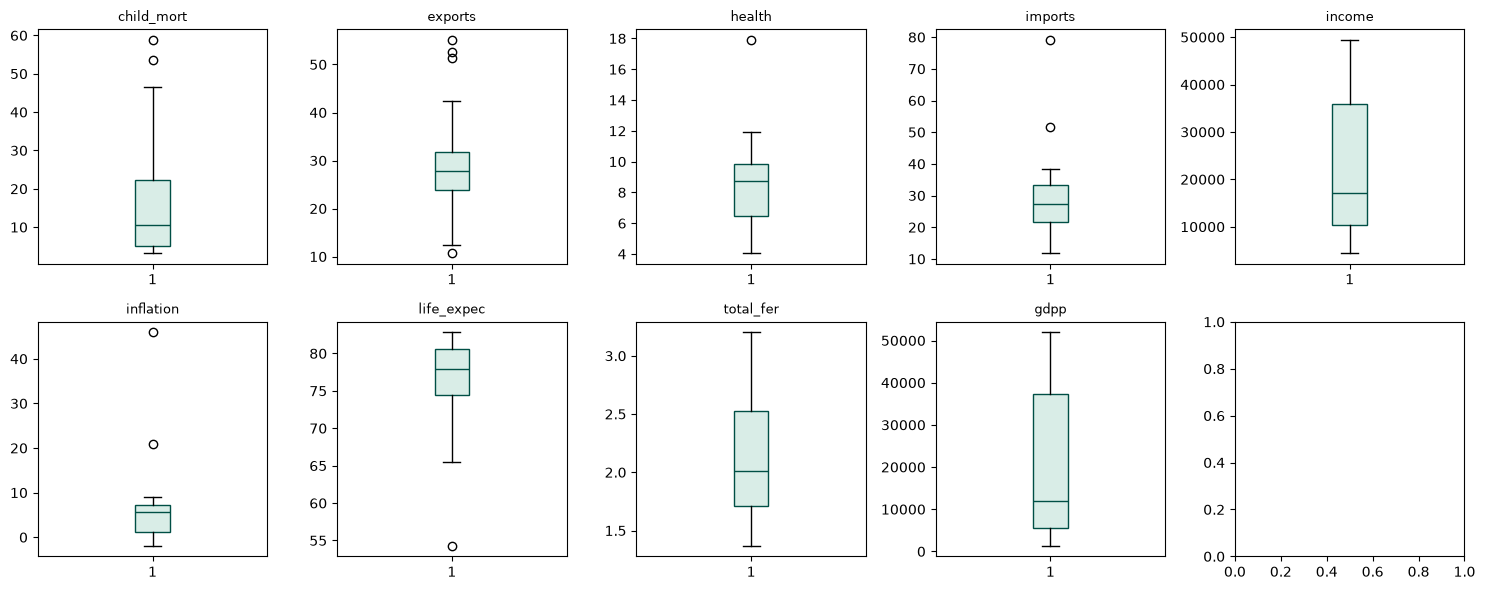

In [23]:
fig, axes = plt.subplots(2, 5, figsize=(15, 6))
for ax, col in zip(axes.ravel(), df2.columns):
    ax.boxplot(df2[col], patch_artist=True,
               boxprops=dict(facecolor="#D9EDE7", color="#004F45"),
               medianprops=dict(color="#004F45"))
    ax.set_title(col, fontsize=9)
plt.tight_layout()
plt.show()

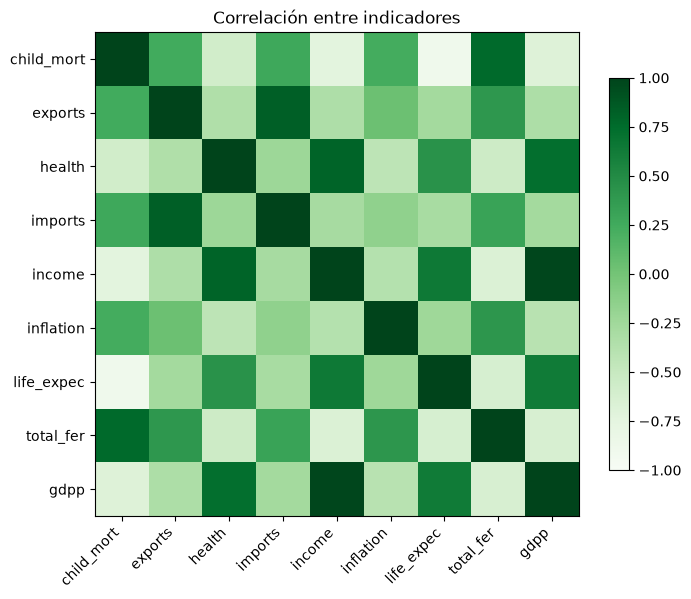

In [24]:
corr2 = df2.corr()
fig, ax = plt.subplots(figsize=(7.2, 6))
im = ax.imshow(corr2, cmap="Greens", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr2)))
ax.set_xticklabels(corr2.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr2)))
ax.set_yticklabels(corr2.columns)
fig.colorbar(im, ax=ax, shrink=0.8)
ax.set_title("Correlación entre indicadores")
plt.tight_layout()
plt.show()

Las variables tienen magnitudes muy distintas: `gdpp` e `income` se miden en miles de dólares, mientras que `child_mort` es un porcentaje y `total_fer` una tasa. Sin preparar los datos, `gdpp` dominaría la distancia euclidiana. Se construyen dos matrices: una con los valores originales y otra estandarizada.

In [25]:
X2 = df2.copy()
scaler2 = StandardScaler()
X2_scaled = pd.DataFrame(scaler2.fit_transform(X2), index=X2.index, columns=X2.columns)
print("rango original:")
print(X2.agg(["min", "max"]).round(2))
print("rango estandarizado:")
print(X2_scaled.agg(["min", "max"]).round(2))

rango original:
     child_mort  exports  health  imports  income  inflation  life_expec  total_fer   gdpp
min         3.2     10.7    4.05     11.8    4410       -1.9        54.3       1.37   1350
max        58.8     55.1   17.90     79.1   49400       45.9        82.8       3.20  51900
rango estandarizado:
     child_mort  exports  health  imports  income  inflation  life_expec  total_fer  gdpp
min       -0.89    -1.65   -1.57    -1.33   -1.32      -0.94       -3.51      -1.45 -1.11
max        2.72     2.30    3.21     3.81    2.03       4.43        1.04       2.28  1.85


## 2. Construir la jerarquía y leer el dendrograma

Se comparan los cuatro enlaces: `single`, `complete`, `average` y `ward`. Los tres primeros usan distancias entre puntos; `ward` minimiza la varianza dentro de los grupos y suele producir grupos más compactos.

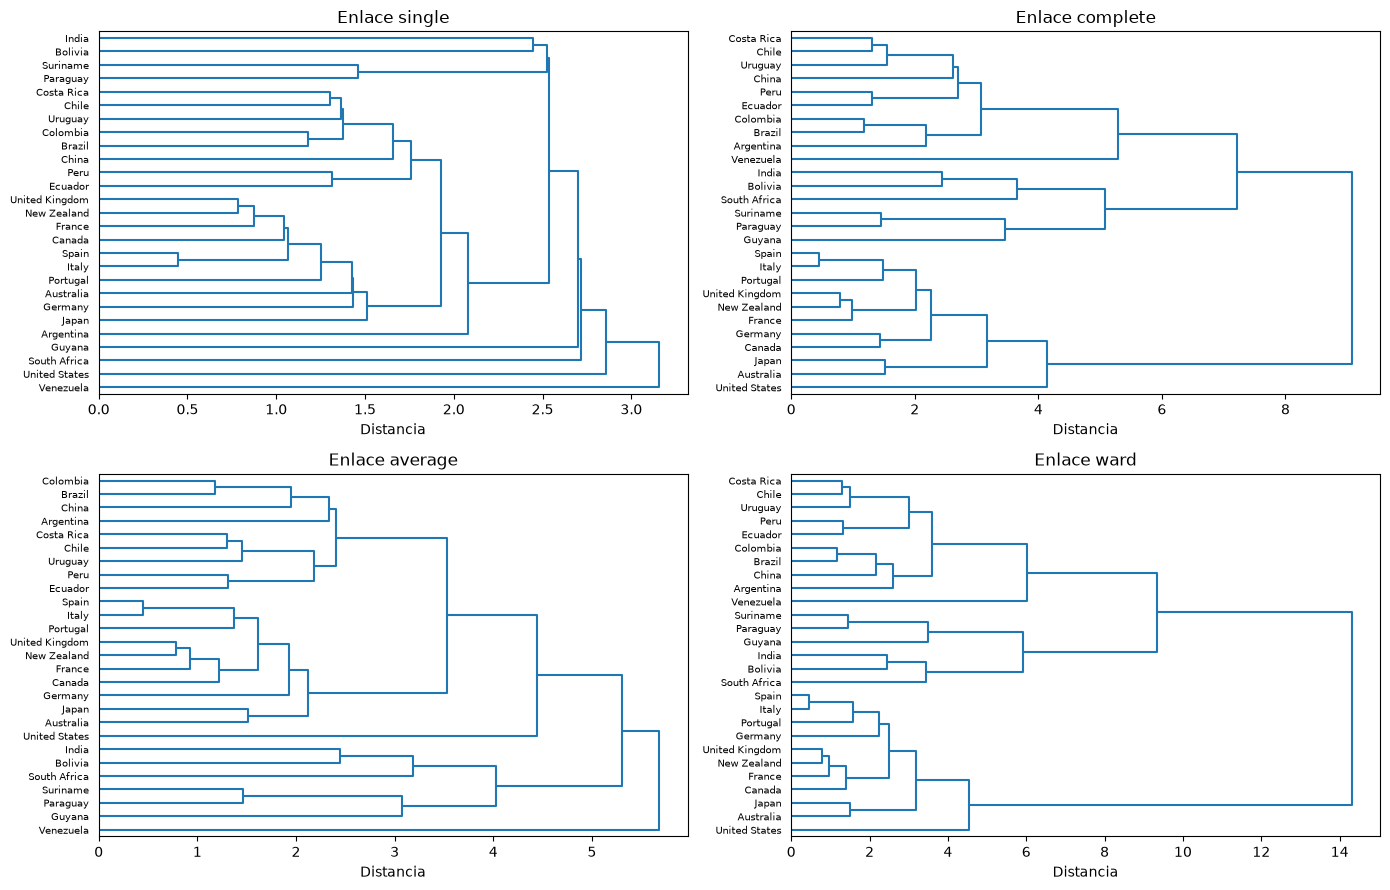

In [26]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, metodo in zip(axes.ravel(), ["single", "complete", "average", "ward"]):
    Z = linkage(X2_scaled, method=metodo)
    dendrogram(Z, labels=X2_scaled.index, orientation="right",
               leaf_font_size=7, ax=ax, color_threshold=0)
    ax.set_title(f"Enlace {metodo}")
    ax.set_xlabel("Distancia")
plt.tight_layout()
plt.show()

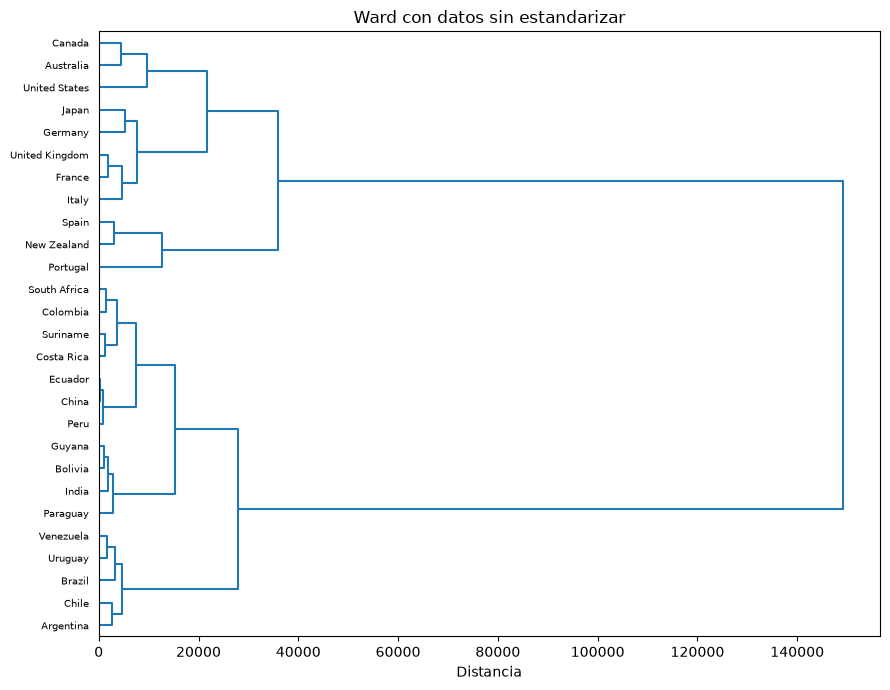

In [27]:
Z_sin = linkage(X2, method="ward")
fig, ax = plt.subplots(figsize=(9, 7))
dendrogram(Z_sin, labels=X2.index, orientation="right",
           leaf_font_size=7, ax=ax, color_threshold=0)
ax.set_title("Ward con datos sin estandarizar")
ax.set_xlabel("Distancia")
plt.tight_layout()
plt.show()

**Comparación de formas.** `single` encadena países con un solo vecino cercano y produce cadenas largas; `complete` y `average` forman grupos más equilibrados; `ward` entrega la estructura más compacta y legible. Al quitar la estandarización, `gdpp` e `income` dominan y el dendrograma cambia: los países se ordenan casi por ingreso y se pierden matices de salud y fertilidad. La predicción se cumplió: la escala cambia la jerarquía.

## 3. Cortar la jerarquía

Se usa el enlace `ward` con datos estandarizados. Se prueban cortes de 2 a 5 grupos, se calcula la silueta de cada corte y se elige el que combine separación y utilidad para describir los grupos.

In [28]:
Z = linkage(X2_scaled, method="ward")
resultados = []
for k in range(2, 6):
    labels = fcluster(Z, t=k, criterion="maxclust")
    resultados.append({
        "k": k,
        "silueta": silhouette_score(X2_scaled, labels),
        "tamanos": sorted(pd.Series(labels).value_counts().tolist(), reverse=True),
    })
pd.DataFrame(resultados).round(3)

,k,silueta,tamanos
0,2,0.352,"[16, 11]"
1,3,0.348,"[11, 10, 6]"
2,4,0.338,"[11, 9, 6, 1]"
3,5,0.363,"[11, 9, 3, 3, 1]"


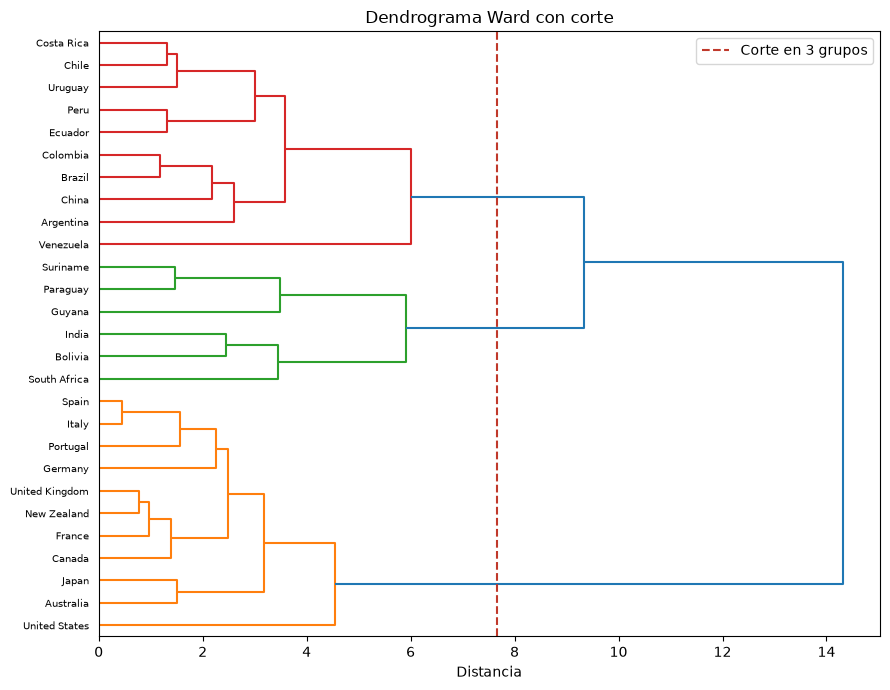

In [29]:
k2 = 3
labels_jer = fcluster(Z, t=k2, criterion="maxclust")
altura = (Z[len(Z) - k2, 2] + Z[len(Z) - k2 + 1, 2]) / 2

fig, ax = plt.subplots(figsize=(9, 7))
dendrogram(Z, labels=X2_scaled.index, orientation="right",
           leaf_font_size=7, ax=ax, color_threshold=altura)
ax.axvline(altura, color="#C0392B", linestyle="--", linewidth=1.5,
           label=f"Corte en {k2} grupos")
ax.set_title("Dendrograma Ward con corte")
ax.set_xlabel("Distancia")
ax.legend()
plt.tight_layout()
plt.show()

La silueta es 0,348 para k = 3, 0,338 para k = 4 y 0,363 para k = 5. La diferencia con k = 5 es pequeña, pero ese corte produce un grupo de un solo país y dos grupos de tres; k = 3 entrega tamaños 11, 10 y 6, más estables y descriptibles. El salto de altura más grande aparece al pasar de 3 a 2 grupos: cortar en 2 dejaría grupos demasiado amplios. Entre 4 y 3 el salto es menor, pero 3 evita singletons y mantiene grupos descriptibles. Por eso se elige **k = 3**: la silueta es competitiva, los grupos son interpretables y no hay singletons. La altura del dendrograma mide disimilitud, no calidad; el corte se justifica con la silueta, el salto de altura y la utilidad de los grupos.

In [30]:
df2["cluster_jer"] = labels_jer
perfil2 = df2.groupby("cluster_jer").agg(
    paises=("child_mort", "count"),
    mortalidad=("child_mort", "mean"),
    esperanza=("life_expec", "mean"),
    ingreso=("income", "mean"),
    gdpp=("gdpp", "mean"),
).round(1)
perfil2

,paises,mortalidad,esperanza,ingreso,gdpp
cluster_jer,,,,,
1,11,4.8,81.0,37181.8,39654.5
2,6,40.8,67.0,8191.7,4196.7
3,10,16.1,76.7,13894.0,8849.0


In [31]:
for grupo in sorted(df2["cluster_jer"].unique()):
    miembros = sorted(df2.index[df2["cluster_jer"] == grupo].tolist())
    print(f"Grupo {grupo} ({len(miembros)}):")
    print(", ".join(miembros))
    print()

Grupo 1 (11):
Australia, Canada, France, Germany, Italy, Japan, New Zealand, Portugal, Spain, United Kingdom, United States

Grupo 2 (6):
Bolivia, Guyana, India, Paraguay, South Africa, Suriname

Grupo 3 (10):
Argentina, Brazil, Chile, China, Colombia, Costa Rica, Ecuador, Peru, Uruguay, Venezuela



## 4. Comparar con K-means

Se ajusta K-means con el mismo número de grupos sobre la matriz estandarizada y se compara la partición con una tabla de contingencia y el índice de Rand ajustado.

In [32]:
km2 = KMeans(n_clusters=k2, n_init=10, random_state=SEED)
labels_km2 = km2.fit_predict(X2_scaled)
df2["cluster_km"] = labels_km2

print("ARI jerárquico vs. K-means:", round(adjusted_rand_score(labels_jer, labels_km2), 3))
pd.crosstab(df2["cluster_jer"], df2["cluster_km"],
            rownames=["Jerárquico"], colnames=["K-means"])

ARI jerárquico vs. K-means: 1.0


K-means,0,1,2
Jerárquico,,,
1,11,0,0
2,0,0,6
3,0,10,0


In [33]:
comparacion2 = df2.groupby("cluster_km").agg(
    paises=("child_mort", "count"),
    mortalidad=("child_mort", "mean"),
    esperanza=("life_expec", "mean"),
    ingreso=("income", "mean"),
    gdpp=("gdpp", "mean"),
).round(1)
comparacion2

,paises,mortalidad,esperanza,ingreso,gdpp
cluster_km,,,,,
0,11,4.8,81.0,37181.8,39654.5
1,10,16.1,76.7,13894.0,8849.0
2,6,40.8,67.0,8191.7,4196.7


**Respuesta y comparación.** Chile se agrupa con Argentina, Brasil, Colombia, Costa Rica, Ecuador, Perú, Uruguay, Venezuela y China: mortalidad infantil intermedia, esperanza de vida alta e ingreso medio. La hipótesis se cumplió en parte, porque también entraron países fuera del Cono Sur. K-means y Ward coinciden completamente (ARI = 1,0); solo cambian las etiquetas.

**Método y limitación.** Presentaría el jerárquico porque el dendrograma muestra los niveles de agrupación y permite explicar con quién se une Chile sin fijar k. Los grupos dependen de las variables, la estandarización y la distancia; no son un ranking ni permiten concluir que un país sea mejor que otro.

# Cierre

- K-means y el clustering jerárquico responden a ideas distintas de grupo: el primero optimiza centroides y el segundo construye una jerarquía de fusiones.
- La estandarización es una decisión de modelado, no un trámite: cambia la geometría y los grupos.
- La evidencia debe combinar métricas, estabilidad y utilidad; un codo o una silueta aislados no bastan.
- Los grupos son hipótesis descriptivas, no verdades ocultas ni rankings.

In [34]:
import sklearn, scipy
print("pandas", pd.__version__)
print("scikit-learn", sklearn.__version__)
print("scipy", scipy.__version__)

pandas 3.1.1
scikit-learn 1.9.1
scipy 1.18.1
